[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/26_llm_post_training.ipynb)

# 26 · LLM Post-Training: SFT, RLHF, DPO, and GRPO

**Part 5 — Transformers & LLMs** · Notebook 26 of 27 (the last one)

Notebook 25 ended with a pretrained language model: a superb imitator of its training text, and nothing more. Ask it a question and it continues the way text on the internet tends to continue, which may be an answer, more questions, or confident nonsense. Everything that turns a pretrained model into a helpful assistant happens afterwards, in **post-training** (CX 4240 lecture 23): **supervised fine-tuning** on demonstrations of good behavior, then learning from **feedback**, either as rewards (reinforcement learning: RLHF with PPO, GRPO) or directly from preference pairs (DPO).

Real post-training uses billions of parameters and expensive human feedback. To see every moving part clearly, we'll run the whole pipeline on a **toy world small enough to train in minutes on a CPU**: a tiny transformer that answers addition questions. Its "internet" pretraining data is full of wrong answers, so the base model is unreliable; we then fix it with each post-training method in turn and compare. First, a short primer on reinforcement learning, which the rest of the notebook builds on.

**What you'll learn**

1. Reinforcement learning in one page: policies, rewards, and the policy gradient
2. A bandit warm-up: learning from rewards alone
3. The toy world: a tiny GPT pretrained on noisy "internet" arithmetic
4. **Supervised fine-tuning (SFT)**
5. **Reward models** from pairwise preferences (Bradley–Terry)
6. **RLHF**: policy gradient with a KL leash, PPO-style
7. **DPO**: preferences as classification, no reward model, no sampling
8. **GRPO**: group-relative advantages with verifiable rewards
9. Head to head, and the KL trade-off
10. Reward hacking, and what real post-training looks like

*Course map: CX 4240 lecture 23 ((Large) Language Model Part II: Post-Training: is pretraining enough?, supervised fine-tuning / instruction tuning as MLE on prompt–answer pairs, RLHF with preference data, PPO vs. DPO vs. GRPO, DPO as classification, online vs. offline samples, learning a reward model + policy gradient) and lecture 22's overview of LLM training stages (unlabeled text → prompt & answer → preference data → agentic RL).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import math, time, copy
torch.manual_seed(0)
device = "cpu"                     # everything here is tiny; the CPU is fastest
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. Reinforcement learning in one page

Supervised learning has a correct answer for every input. Reinforcement learning (RL) has only a **reward**: a number saying how good an outcome was, with no indication of what the right action would have been.

- A **policy** $\pi_\theta(a \mid s)$ is a probability distribution over **actions** $a$ given a **state** $s$. For an LLM, the state is the prompt (plus what's been generated so far), an action is the next token, and a complete response $y$ is a sequence of actions: $\pi_\theta(y \mid x) = \prod_t \pi_\theta(y_t \mid x, y_{<t})$.
- A **reward** $r(x, y)$ scores the outcome. In LLM post-training it usually arrives once, for the whole response.
- The goal: maximize the expected reward $J(\theta) = \mathbb{E}_{y \sim \pi_\theta(\cdot \mid x)}\big[r(x, y)\big]$.

The difficulty: $y$ is *sampled* from the policy, and sampling discrete tokens isn't differentiable (the reparameterization trick of notebook 23 needs continuous variables). The **policy gradient** theorem (the score-function estimator from notebook 23) gets around it:

$$\nabla_\theta J = \mathbb{E}_{y \sim \pi_\theta}\big[r(x, y)\,\nabla_\theta\log\pi_\theta(y \mid x)\big] \;\approx\; \frac{1}{N}\sum_{i=1}^{N} r(x, y_i)\,\nabla_\theta\log\pi_\theta(y_i \mid x).$$

In words: sample some responses, then **raise the log-probability of each one in proportion to its reward**. It's the gradient of a *weighted* log-likelihood, so it looks just like supervised learning on the model's own samples, with rewards as weights. This is the REINFORCE algorithm (Williams, 1992).

Two refinements matter enormously in practice:

- **Baselines.** Subtracting any constant $b$ from the reward doesn't change the expected gradient (because $\mathbb{E}[\nabla\log\pi] = 0$) but can slash its variance. Using $A = r - b$, the **advantage** (how much better than usual this response was), pushes up good samples and *down* bad ones.
- **Staying close.** Large policy updates can wreck a model. PPO clips how far each update can move the probabilities; and in LLMs a **KL penalty** keeps the fine-tuned policy close to a reference model.

---
## 2. A bandit warm-up

The simplest RL problem: a **multi-armed bandit** with 5 slot machines. Every pull pays 2 points, plus 1 bonus point with an unknown, machine-specific probability. (Rewards that are always positive are common: a reward model's scores have no natural zero.) The policy is a softmax over 5 preferences $\theta$; there's no state. We learn by pulling arms and applying REINFORCE, with and without a baseline (the running average reward):

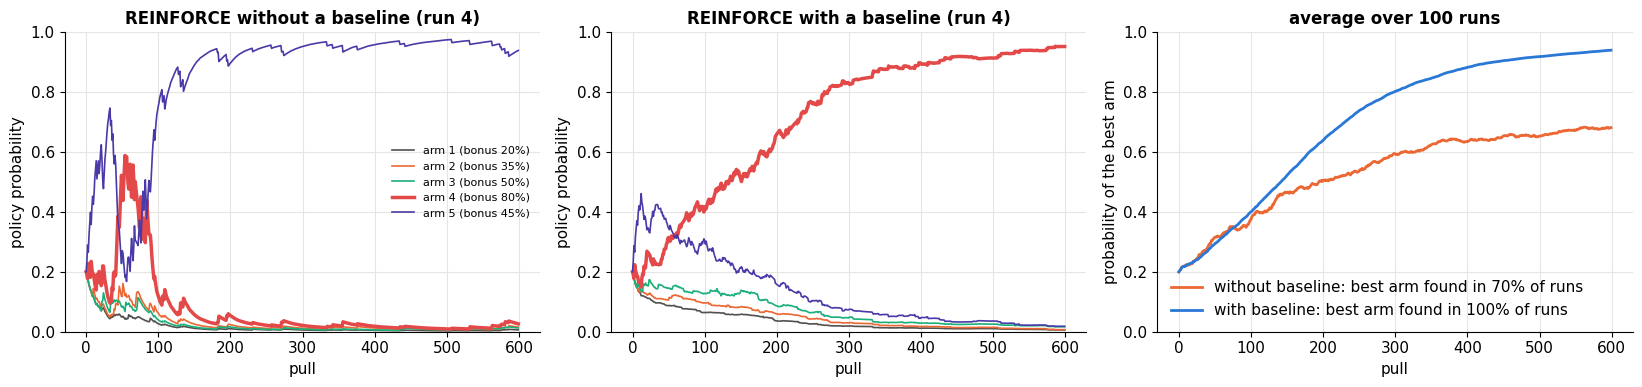

In [2]:
p_true = np.array([0.2, 0.35, 0.5, 0.8, 0.45])            # bonus probabilities; arm 4 (index 3) is best
def run_bandit(steps=600, lr=0.1, baseline=True, seed=0):
    r = np.random.default_rng(seed); theta = np.zeros(5); avg = 0.0; probs_hist, rewards = [], []
    for t in range(steps):
        pi = np.exp(theta - theta.max()); pi /= pi.sum()
        a = r.choice(5, p=pi); reward = 2.0 + float(r.random() < p_true[a])      # 2 points always, 3 with a bonus
        adv = reward - (avg if baseline else 0.0)
        grad_logpi = -pi; grad_logpi[a] += 1                 # ∇θ log softmax(θ)[a] = onehot(a) − π
        theta += lr * adv * grad_logpi
        avg += 0.05 * (reward - avg); probs_hist.append(pi); rewards.append(reward)
    return np.array(probs_hist), np.array(rewards)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, bl in zip(axes[:2], [False, True]):
    ph, _ = run_bandit(baseline=bl, seed=4)           # one example run (seed 4)
    for k, col in enumerate([C["muted"], C["orange"], C["aqua"], C["red"], C["violet"]]):
        ax.plot(ph[:, k], color=col, lw=2.5 if k == 3 else 1.2, label=f"arm {k + 1} (bonus {p_true[k]:.0%})")
    ax.set(xlabel="pull", ylabel="policy probability", ylim=(0, 1), title=f"REINFORCE {'with' if bl else 'without'} a baseline (run 4)")
axes[0].legend(fontsize=8)
for bl, col in [(False, C["orange"]), (True, C["blue"])]:
    runs = np.array([run_bandit(baseline=bl, seed=s)[0][:, 3] for s in range(100)])
    axes[2].plot(runs.mean(0), color=col, label=f"{'with' if bl else 'without'} baseline: best arm found in {np.mean(runs[:, -1] > 0.5):.0%} of runs")
axes[2].set(xlabel="pull", ylabel="probability of the best arm", ylim=(0, 1), title="average over 100 runs"); axes[2].legend()
fig.tight_layout(); plt.show()

Without a baseline, *every* pull earns at least 2 points, so every pull pushes its own arm **up**: whichever arm happens to be pulled most early on gets reinforced most, the rich get richer, and a good fraction of runs lock onto a mediocre arm (run 4, left, settles on arm 5). With the baseline, only better-than-average outcomes push their arm up and worse-than-average ones push it **down**, so the constant 2 points cancel out and every run finds the best arm. (With rewards of exactly 0 or 1 the difference is much smaller; try it by deleting the `2.0 +`.) Every method in this notebook is some version of "raise the probability of better-than-expected responses, lower the worse ones, and don't move too far at once".

---
## 3. The toy world

**The task:** answer addition questions like `7+5=` with the sum, then end the line.

**The "internet":** our pretraining corpus contains many such lines, but like real web text it's unreliable: only **55%** of the lines give the correct sum; the rest give a random number. A model pretrained on this learns to imitate it, mistakes included.

**The model:** a tiny GPT (the same architecture as notebook 25: two layers, four heads, 64 dimensions), about 100,000 parameters.

In [3]:
VOCAB = list("0123456789+=\n")
stoi = {c: i for i, c in enumerate(VOCAB)}; itos = {i: c for c, i in stoi.items()}; V = len(VOCAB); NL = stoi["\n"]
enc = lambda s: [stoi[c] for c in s]; dec = lambda ids: "".join(itos[i] for i in ids)
PAIRS = [(a, b) for a in range(10) for b in range(10)]
prompt_of = lambda a, b: f"{a}+{b}="

def internet_line(rng, p_correct=0.55):
    a, b = rng.integers(0, 10, 2); c = a + b if rng.random() < p_correct else rng.integers(0, 19)
    return f"{a}+{b}={c}\n"
rng_c = np.random.default_rng(0)
corpus = "".join(internet_line(rng_c) for _ in range(60000))
print("a slice of the pretraining corpus:\n" + corpus[:96])

class MHA(nn.Module):
    def __init__(self, d, h, T):
        super().__init__(); self.h = h; self.qkv = nn.Linear(d, 3 * d); self.proj = nn.Linear(d, d); self.register_buffer("mask", torch.tril(torch.ones(T, T)).bool())
    def forward(self, x):
        B, T, D = x.shape; q, k, v = self.qkv(x).split(D, 2); q, k, v = [z.view(B, T, self.h, D // self.h).transpose(1, 2) for z in (q, k, v)]
        w = (q @ k.transpose(-2, -1) / math.sqrt(D // self.h)).masked_fill(~self.mask[:T, :T], float("-inf")).softmax(-1)
        return self.proj((w @ v).transpose(1, 2).reshape(B, T, D))
class Block(nn.Module):
    def __init__(self, d, h, T):
        super().__init__(); self.l1, self.l2 = nn.LayerNorm(d), nn.LayerNorm(d); self.attn = MHA(d, h, T); self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x): x = x + self.attn(self.l1(x)); return x + self.mlp(self.l2(x))
class TinyGPT(nn.Module):
    def __init__(self, d=64, h=4, layers=2, T=16):
        super().__init__(); self.T = T; self.tok = nn.Embedding(V, d); self.pos = nn.Embedding(T, d)
        self.blocks = nn.Sequential(*[Block(d, h, T) for _ in range(layers)]); self.ln = nn.LayerNorm(d); self.head = nn.Linear(d, V)
    def forward(self, idx): return self.head(self.ln(self.blocks(self.tok(idx) + self.pos(torch.arange(idx.shape[1])))))

# Pretraining: next-token prediction on random 16-character windows of the corpus
data = torch.tensor(enc(corpus))
def pretrain(steps=1500, seed=0):
    torch.manual_seed(seed); m = TinyGPT(); opt = torch.optim.AdamW(m.parameters(), lr=3e-3)
    for s in range(steps):
        ix = torch.randint(0, len(data) - 17, (64,)); x = torch.stack([data[i:i + 16] for i in ix]); y = torch.stack([data[i + 1:i + 17] for i in ix])
        loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
    return m
t0 = time.time(); base = pretrain(); print(f"\npretrained a {sum(p.numel() for p in base.parameters()):,}-parameter model in {time.time() - t0:.0f}s")

a slice of the pretraining corpus:
8+6=14
3+0=3
1+8=9
6+9=15
7+5=17
6+0=10
0+7=7
7+0=7
8+0=8
2+4=6
0+0=12
2+6=8
4+9=7
6+9=12
7+3=10



pretrained a 102,797-parameter model in 27s


Now some tools we'll use throughout: sampling a response (digits until a newline), computing $\log\pi(y \mid x)$ for a given response, and evaluating how often the model answers correctly, both with **greedy** decoding (always the most likely token) and with **sampling** at temperature 1 (which reveals the full distribution).

In [4]:
def sample(model, prompts, temperature=1.0, max_new=3, greedy=False, gen=None):
    """prompts: list of strings. Returns list of response strings (without the newline)."""
    idx = torch.tensor([enc(p) for p in prompts]); out = [[] for _ in prompts]; done = torch.zeros(len(prompts), dtype=torch.bool)
    with torch.no_grad():
        for _ in range(max_new):
            logits = model(idx)[:, -1] / temperature
            nxt = logits.argmax(-1) if greedy else torch.multinomial(F.softmax(logits, -1), 1, generator=gen).squeeze(1)
            for i, t in enumerate(nxt.tolist()):
                if not done[i]:
                    if t == NL: done[i] = True
                    else: out[i].append(itos[t])
            idx = torch.cat([idx, nxt[:, None]], 1)
            if done.all(): break
    return ["".join(o) for o in out]

def logprob(model, prompts, responses):
    """log π(response + newline | prompt), summed over response tokens. Differentiable."""
    seqs = [enc(p + r + "\n") for p, r in zip(prompts, responses)]; L = max(len(s) for s in seqs)
    idx = torch.tensor([s + [NL] * (L - len(s)) for s in seqs]); logp = F.log_softmax(model(idx[:, :-1]), -1)
    tok_lp = logp.gather(2, idx[:, 1:, None]).squeeze(2)
    mask = torch.zeros_like(tok_lp)
    for i, (p, s) in enumerate(zip(prompts, seqs)): mask[i, len(p) - 1:len(s) - 1] = 1            # only the response tokens
    return (tok_lp * mask).sum(1)

reward_fn = lambda prompt, resp: float(resp.isdigit() and int(resp) == sum(map(int, prompt[:-1].split("+"))))
all_prompts = [prompt_of(a, b) for a, b in PAIRS]
def evaluate(model, n_samples=20):
    greedy = np.mean([reward_fn(p, r) for p, r in zip(all_prompts, sample(model, all_prompts, greedy=True))])
    g = torch.Generator().manual_seed(123)
    sampled = np.mean([reward_fn(p, r) for _ in range(n_samples) for p, r in zip(all_prompts, sample(model, all_prompts, gen=g))])
    return greedy, sampled

results = {"base (pretrained)": evaluate(base)}
print(f"base model: greedy accuracy {results['base (pretrained)'][0]:.0%}, sampled accuracy {results['base (pretrained)'][1]:.0%}  (the corpus is 55% correct)")
g = torch.Generator().manual_seed(0); print("ten samples for '7+5=':", sample(base, ["7+5="] * 10, gen=g))

base model: greedy accuracy 84%, sampled accuracy 46%  (the corpus is 55% correct)
ten samples for '7+5=': ['11', '11', '1', '12', '6', '9', '12', '2', '12', '14']


---
> 🚧 **This notebook is being written section by section.** The sections above are complete and run top to bottom; more are on the way.